In [1]:
pip install scikit-learn pandas matplotlib seaborn

first we download the scikit learn pandas,matplotliband seaboard the reason for the download is that scikit provides simple and efficient tools for predictive data analysis.whereas the pandas help in data cleaning and manipulation and matplotlib is a visualization tool for the datas

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes


In [3]:
data=load_breast_cancer(as_frame=True)

here we load the data and the as_frame tells the scikit to convert the data into rows and xoloumns instead of a numpy arrays

In [4]:
X,y=data.data,data.target

the x is the input and the y is the target output

In [6]:
print(X.shape, y.value_counts())

(569, 30) target
1    357
0    212
Name: count, dtype: int64


In [7]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278
mean area,0.987357,0.321086,0.986507,1.000000,0.177028
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000


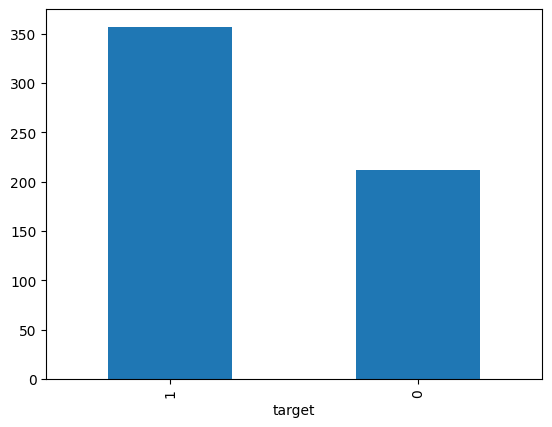

In [8]:
X.describe()
X.isnull().sum().sum()
y.value_counts().plot(kind="bar")
X.iloc[:, :5].corr().style.background_gradient()

describe tells about the information  bout the each category like mean variance and so on and the is null for checking the null values and the bar ,scatterplot for the datas

• test_size=0.2: Reserves 20% of the patients (114 samples) exclusively for testing, using the remaining 80% (455 samples) to train the models.
• random_state=42: Sets a permanent "seed" so that every time you run this code, the rows are shuffled exactly the same way, ensuring reproducible results.

#############################################
• stratify=y: This is crucial for classification tasks. It ensures that the percentage of malignant vs. benign samples remains perfectly identical in both the training set and the testing set, preventing any class imbalance bias.
• fit_transform(X_train): The scaler calculates the exact average and variance of the training data (fit) and immediately scales it (transform).
• transform(X_test): Scales the testing data using the averages calculated from the training data.
• The comment is correct: You never run fit on test data. Doing so causes Data Leakage, meaning your model would accidentally peek at the distribution of the test set before making predictions, leading to overly optimistic and unrealistic performance.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)   # never fit on test data

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    print(name, accuracy_score(y_test, pred))

best = models["Random Forest"]
print(classification_report(y_test, best.predict(X_test_s)))
print(confusion_matrix(y_test, best.predict(X_test_s)))

Logistic Regression 0.9824561403508771
Decision Tree 0.9122807017543859
Random Forest 0.956140350877193
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[39  3]
 [ 2 70]]
